# 05-Dify自定义工具与Function Calling：从插件机制到天气助手

本篇对应课程第 5 章《插件工具应用》，先理解 Function Calling 的工作方式，再看它在 Dify 中如何通过插件实现，最后按“脚本开发、API 运行、自定义工具、Schema、测试、保存”的流程制作智能天气助手。

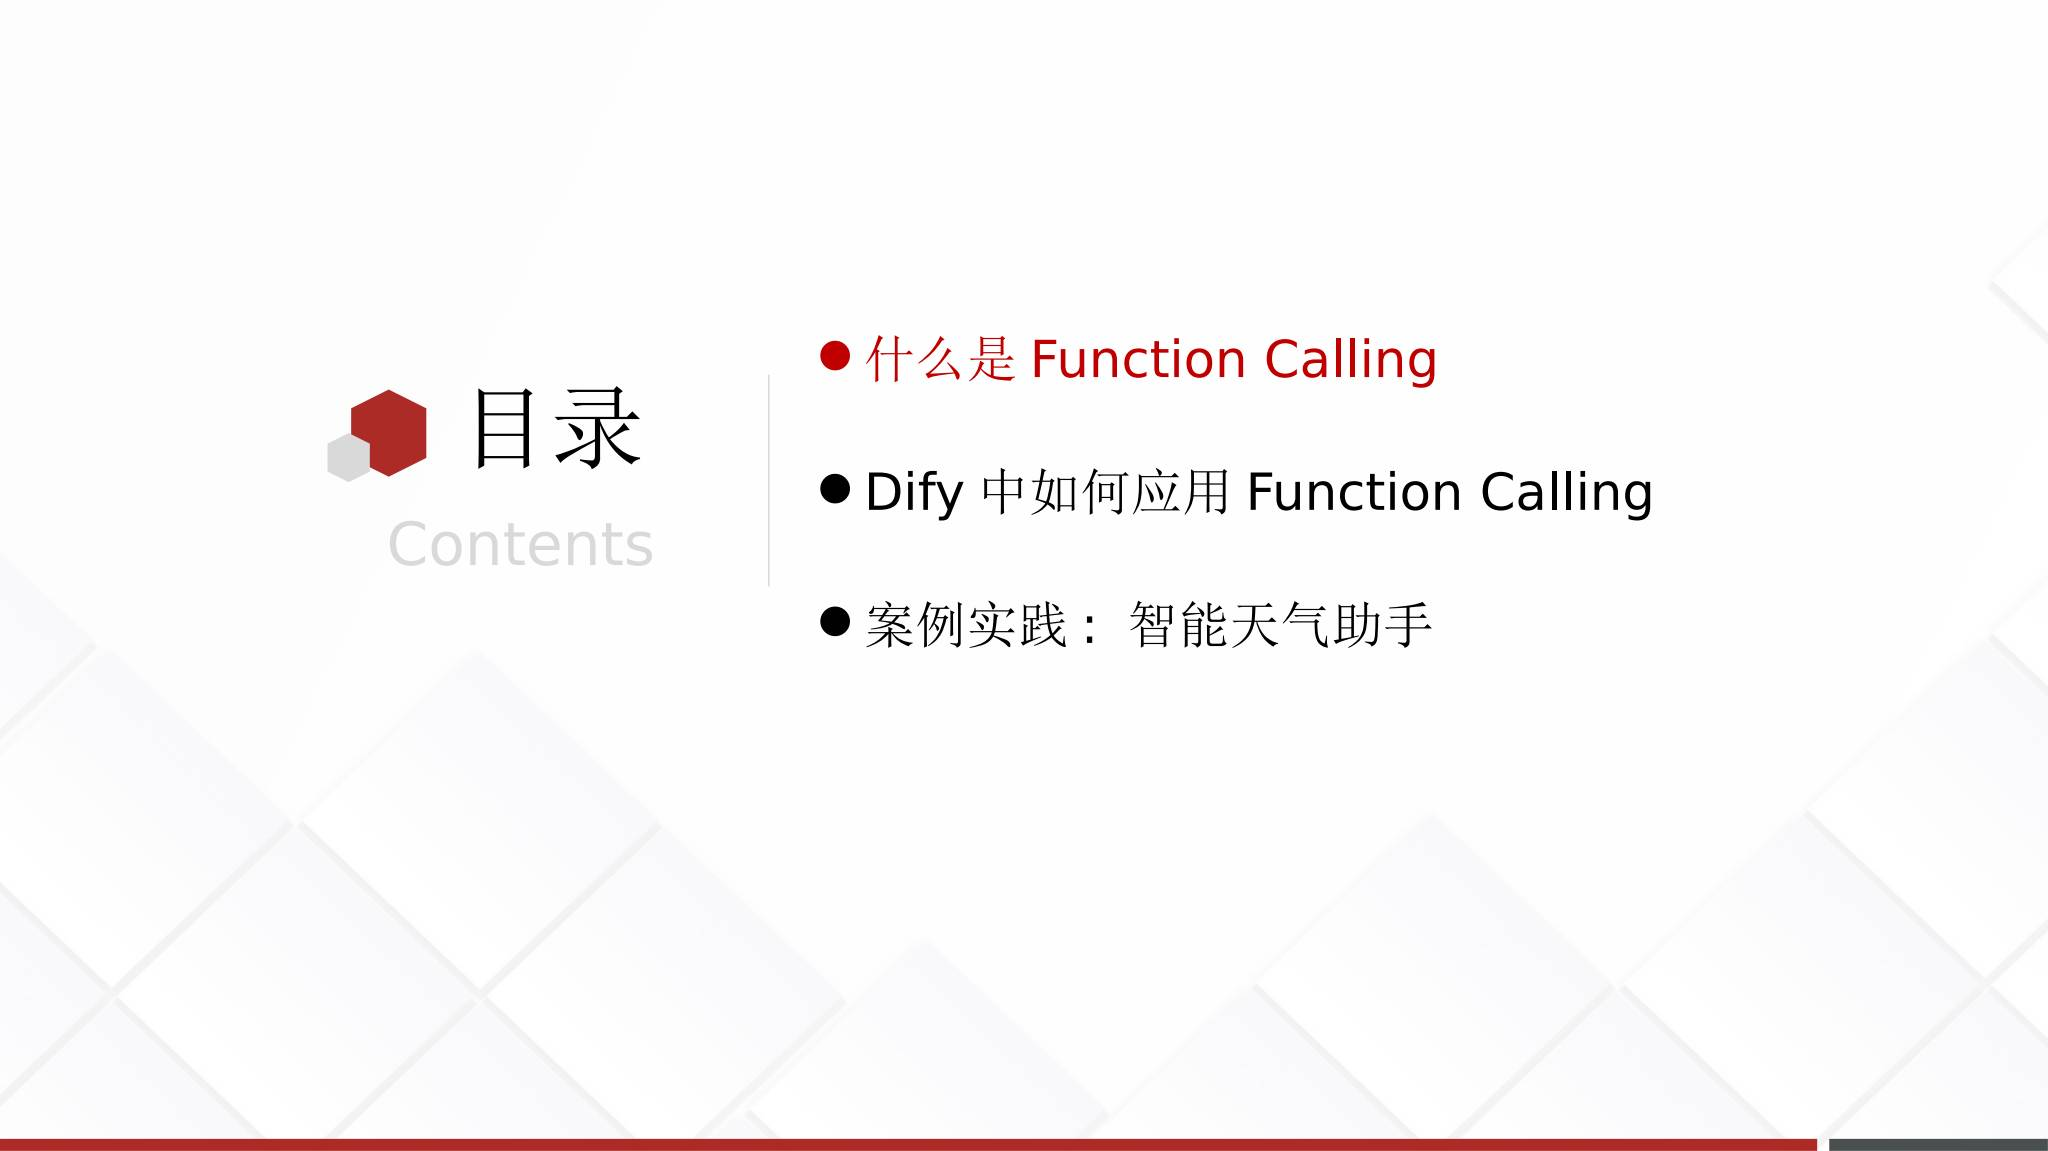


## 1. 什么是 Function Calling

Function Calling（函数调用）是把外部函数或 API 的调用能力接入语言模型。模型在生成回答的过程中，可以判断是否需要外部信息或外部操作，并选择合适的函数。

课程给出的简化流程是：

1. 用户提交请求。
2. 大语言模型判断是否需要调用外部信息。
3. 如果不需要，直接生成回答。
4. 如果需要，匹配外部函数，选择合适的 API，并根据 API 逻辑生成后续回复。

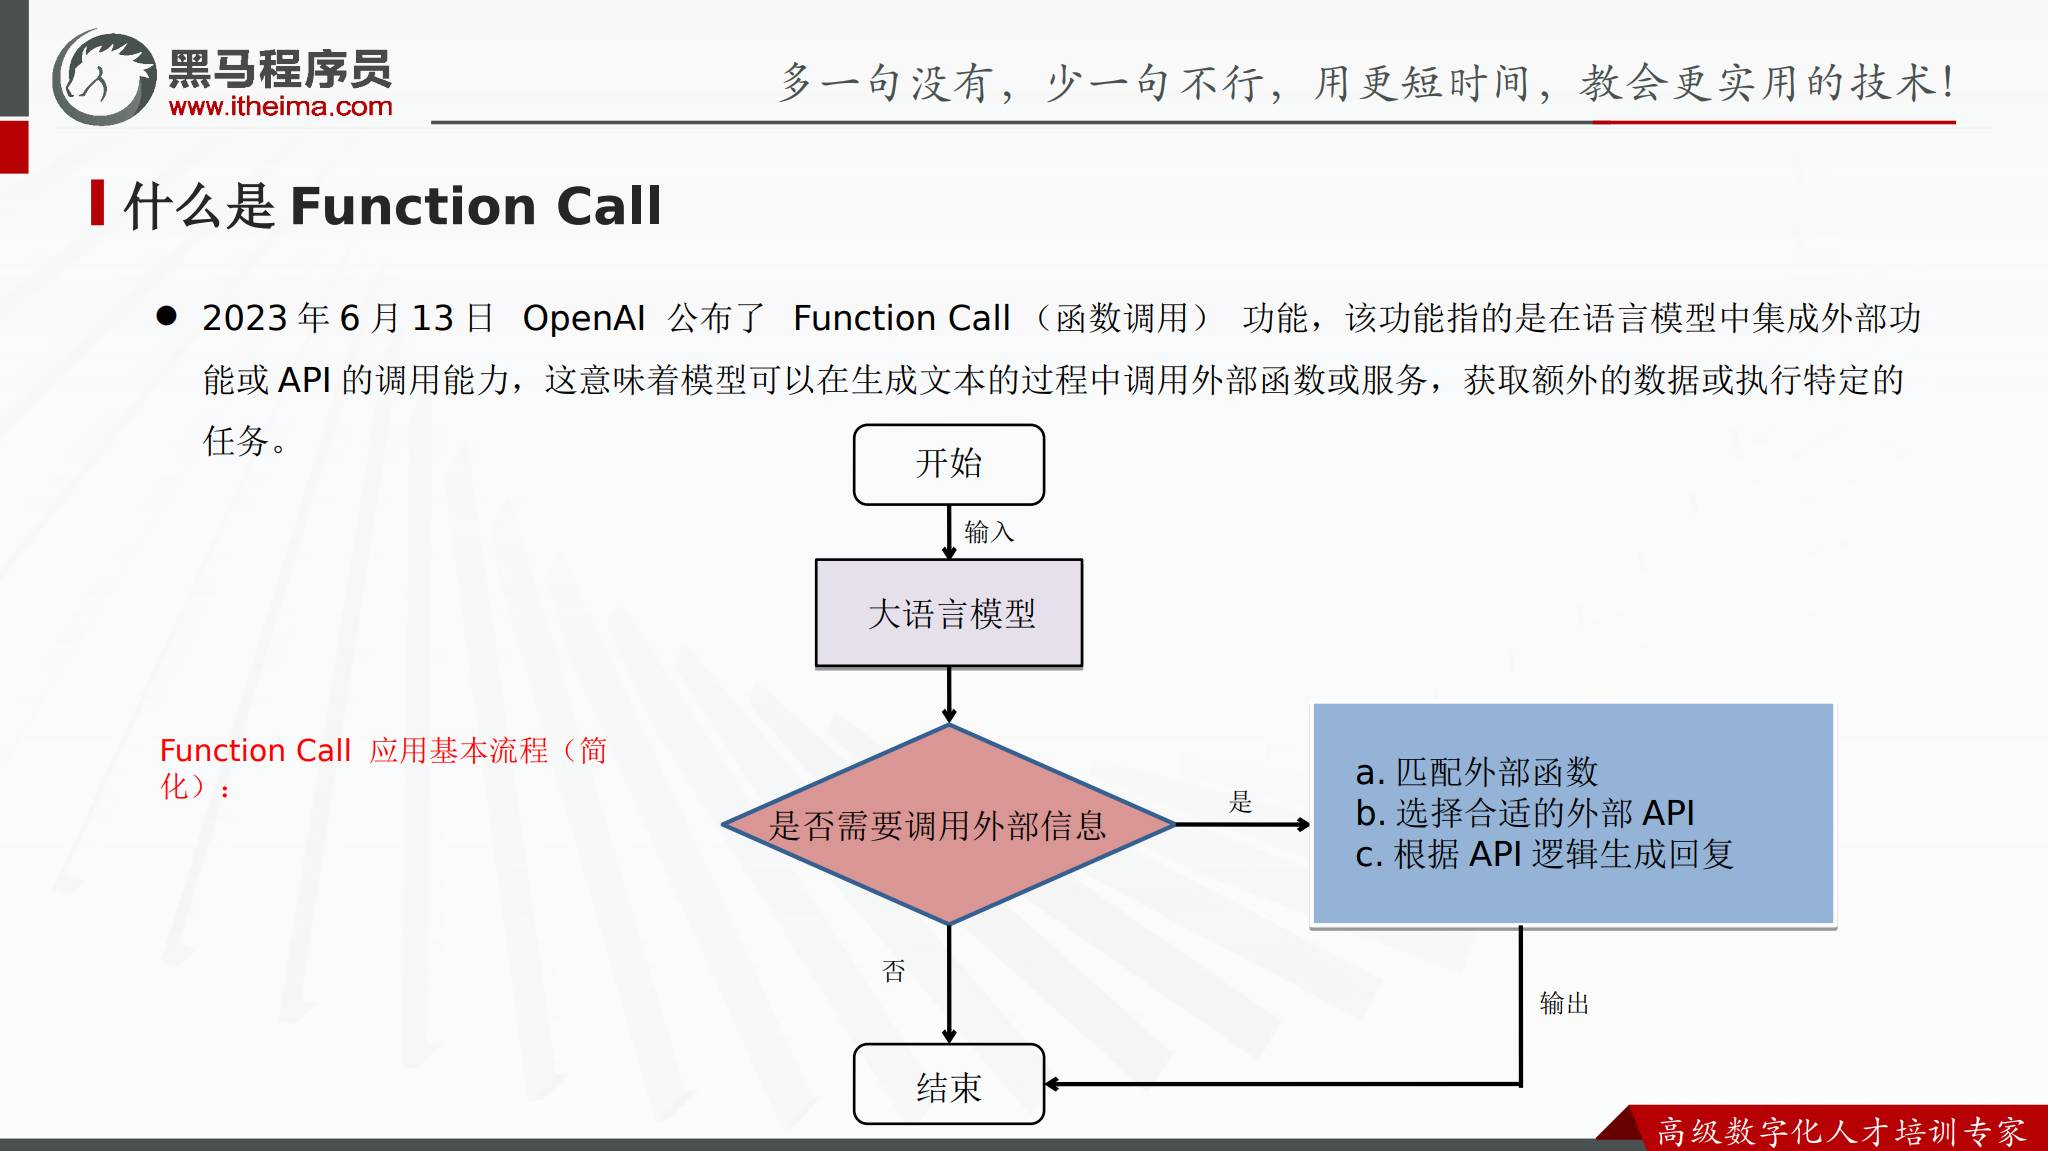


## 2. Function Calling 解决什么问题

课件从三个方面说明函数调用的价值：

| 问题 | 具体表现 | Function Calling 的作用 |
| --- | --- | --- |
| 信息实时性 | 训练数据不包含最新新闻、实时股价等 | 调用外部服务获取最新数据 |
| 数据局限性 | 模型无法覆盖所有专业领域 | 连接外部数据库或 API |
| 功能扩展性 | 模型不可能内置所有功能 | 调用工具完成计算、分析等任务 |

因此，函数调用把模型的语言理解能力和外部系统的实时数据、专业服务连接起来。

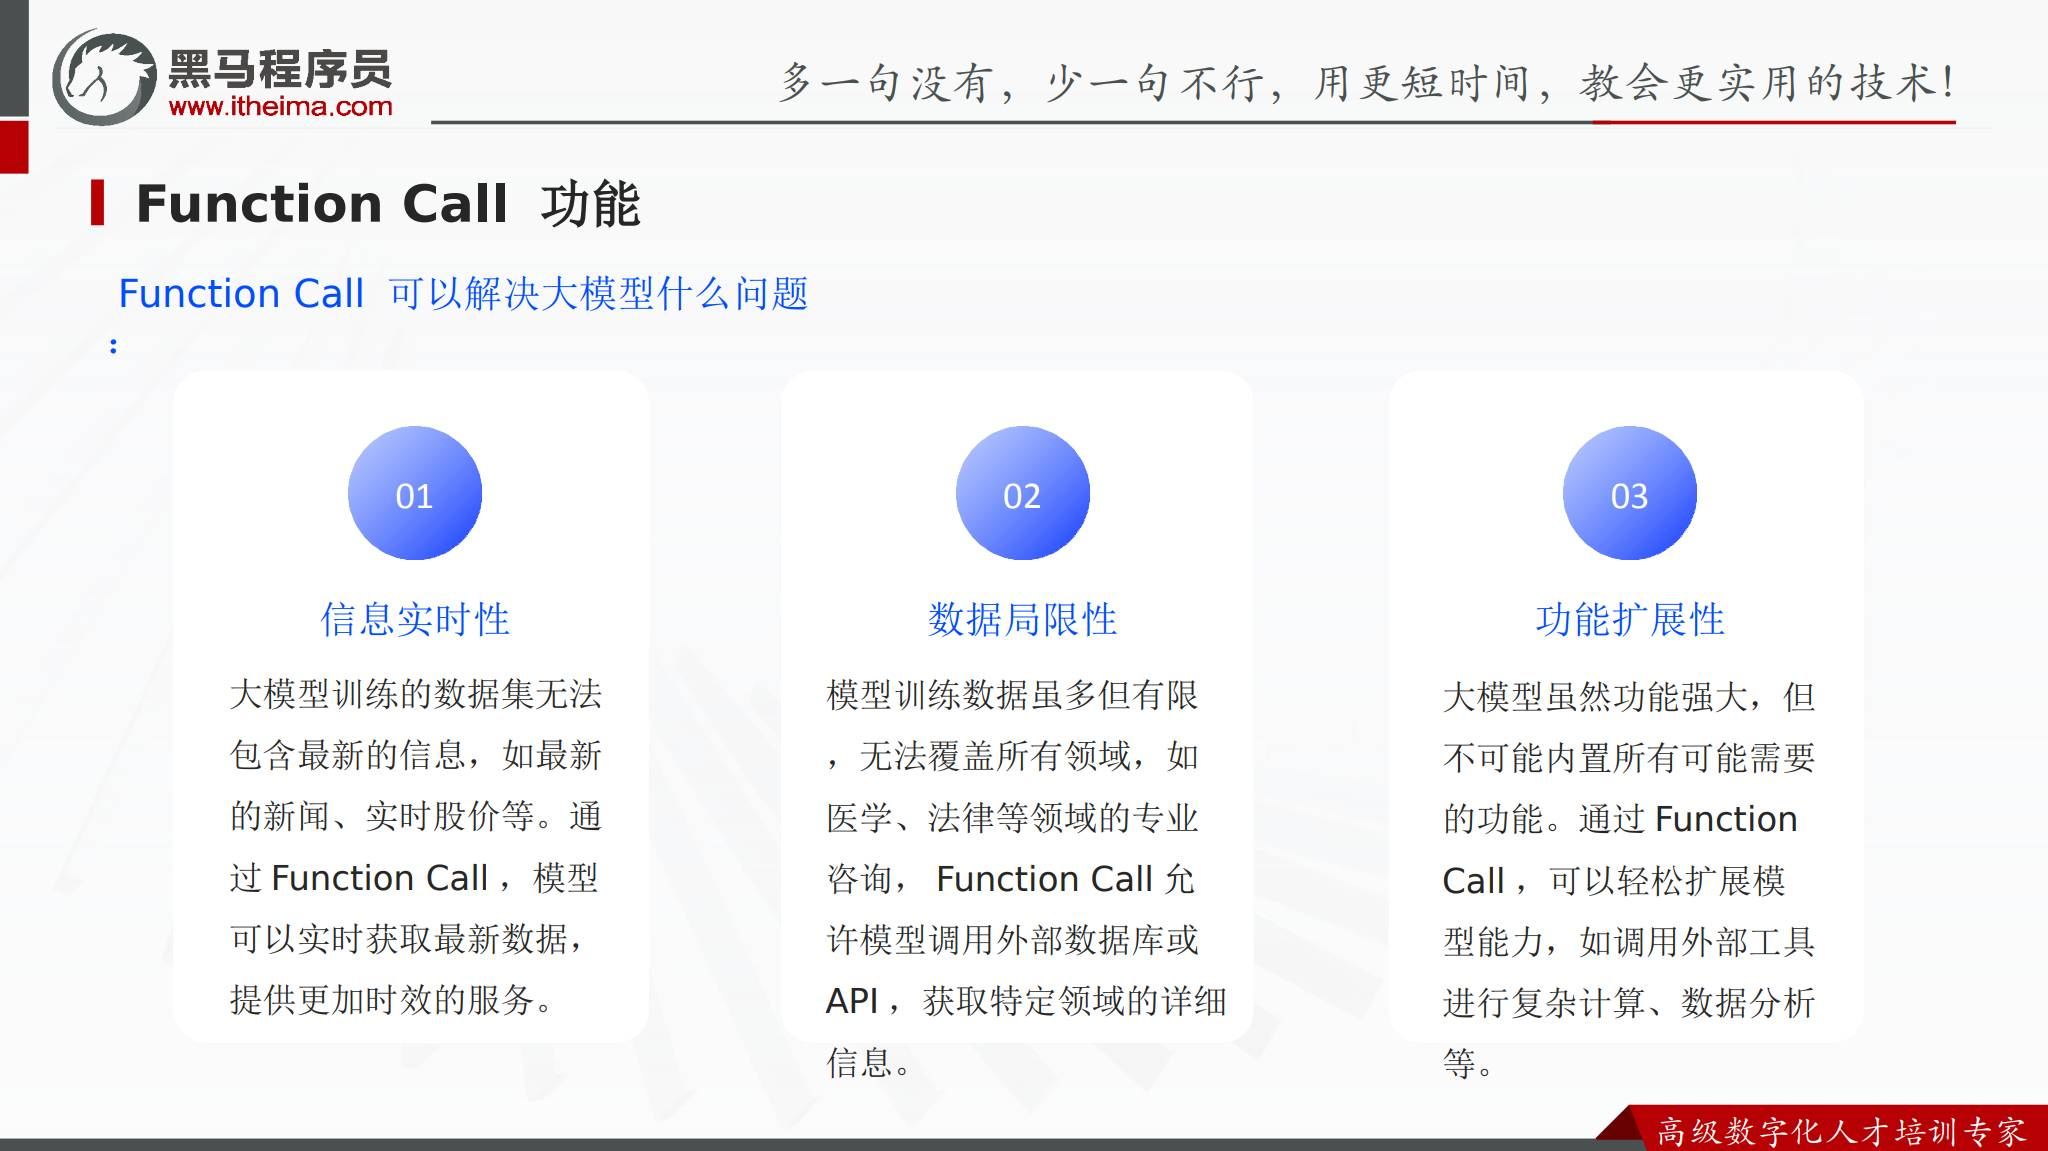


## 3. Function Calling 的工作原理

没有函数调用时，应用流程比较直接：客户端发送请求，服务端把提示词交给 GPT，再把模型文本返回给客户端。

加入函数调用后，流程增加了工具选择和函数执行：

1. 客户端把用户提示词以及可用函数描述发送给服务端。
2. 模型根据提示词判断，返回普通文本，或返回函数调用格式。
3. 如果模型选择函数调用，服务端执行对应函数，并把函数结果返回给模型。
4. 模型使用函数结果生成连贯的文本回复。

关键边界是：**大模型本身不会直接执行函数，它只返回函数调用所需的参数；开发者再利用这些参数在应用中调用函数。**

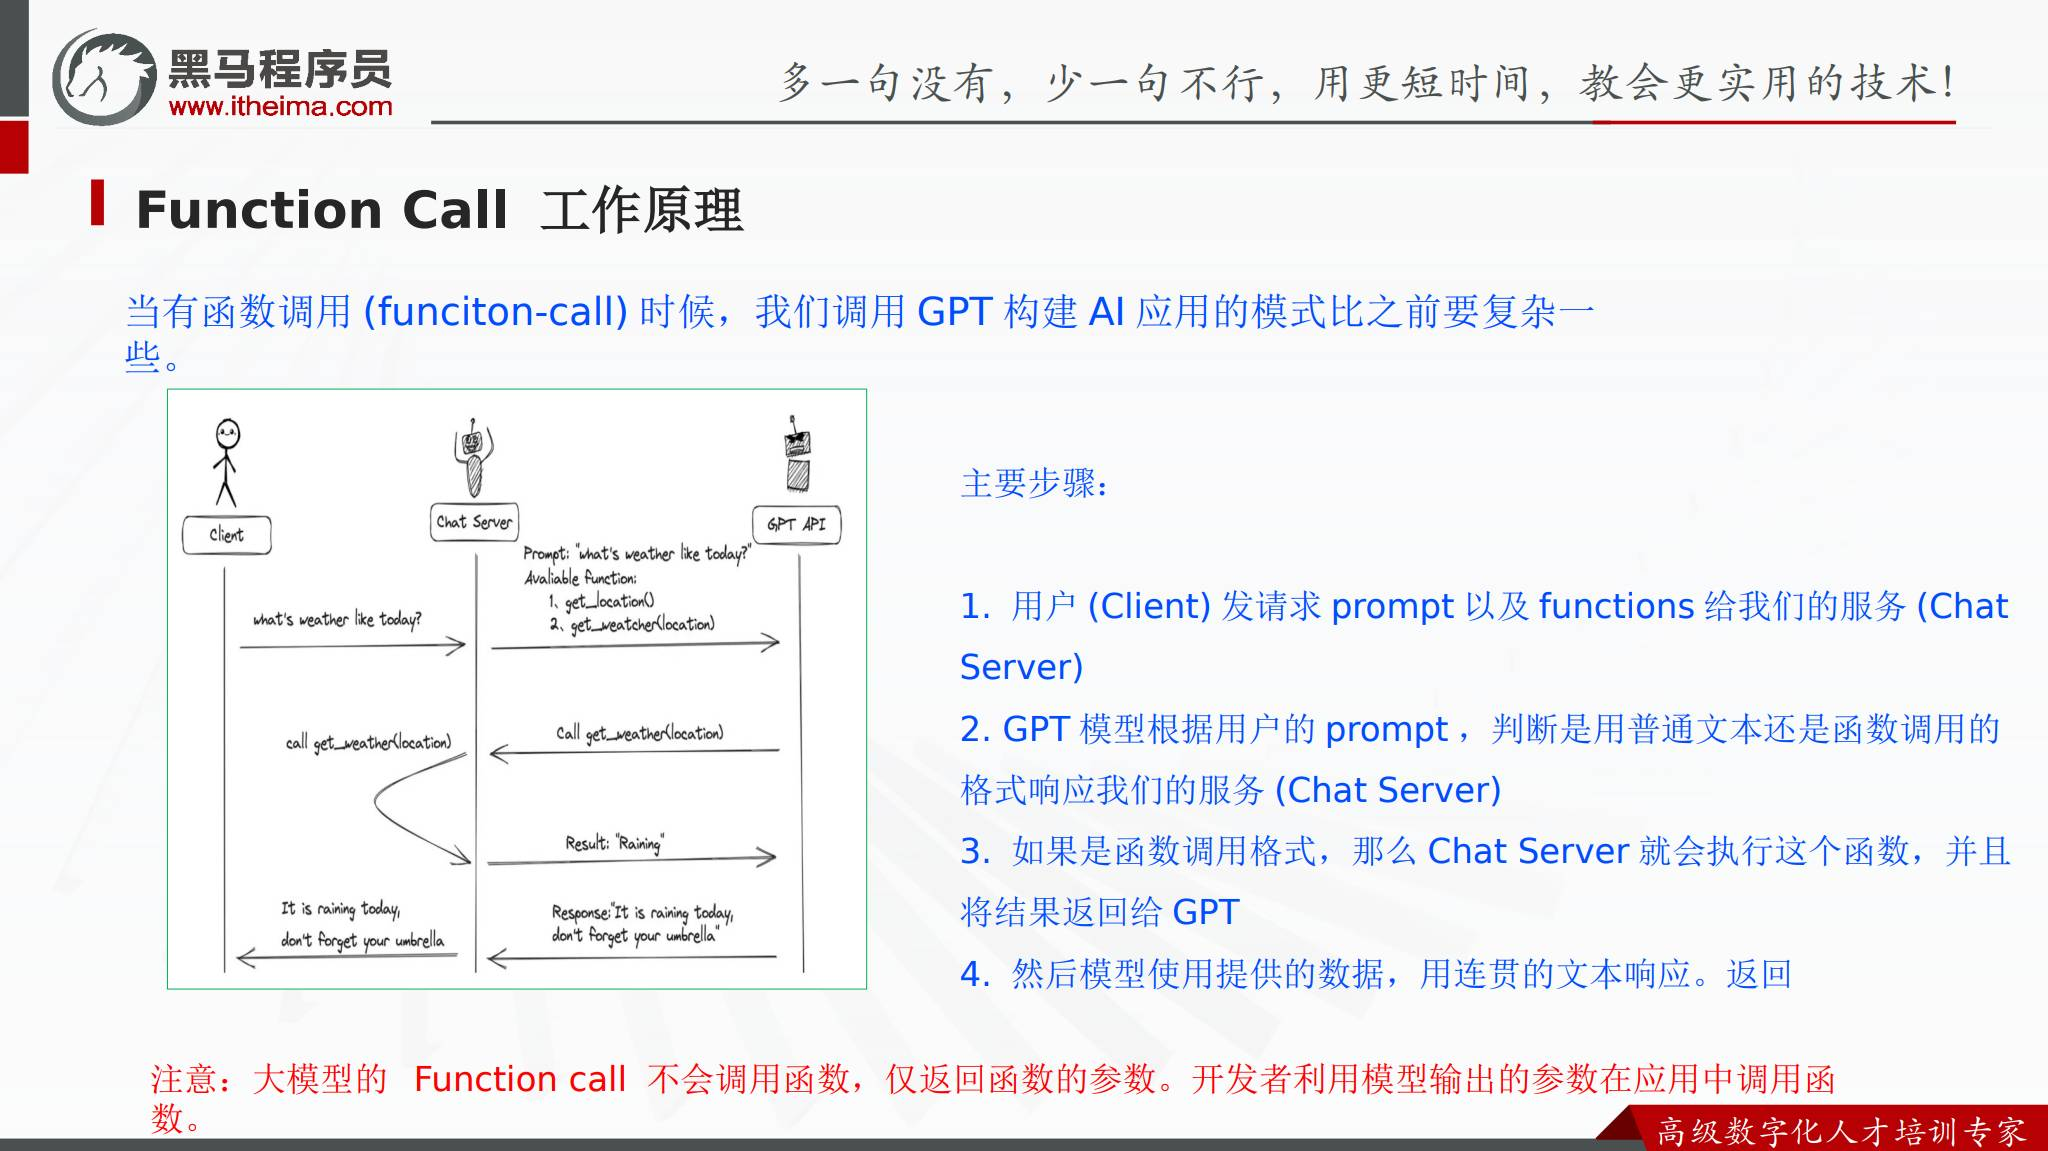


## 4. 一次调用中各部分的职责

可以把职责分成三部分：

| 部分 | 负责内容 |
| --- | --- |
| 大模型 | 理解用户意图，判断是否需要工具，生成工具名和参数，组织最终回答 |
| 应用服务 | 读取模型返回的参数，校验参数，调用真实函数或 API，把结果传回模型 |
| 外部工具 | 提供实时数据或执行具体操作，例如天气、搜索、计算和企业系统接口 |

工具描述会影响模型选择工具的准确性，应用服务则必须负责实际执行和参数安全检查。


## 5. Dify 如何实现 Function Calling

从程序员视角看，Function Calling 是模型调用函数；从 Dify 视角看，工具以**插件**的形式出现：

- 一个插件是一个工具集，可以包含一个或多个工具。
- 每个工具对应一个可调用的 API。
- 模型通过阅读插件描述，决定是否调用该插件。

因此，在 Dify 中使用 Function Calling，重点是准备可理解的插件描述、选择工具，并把工具挂接到 Agent 应用中。

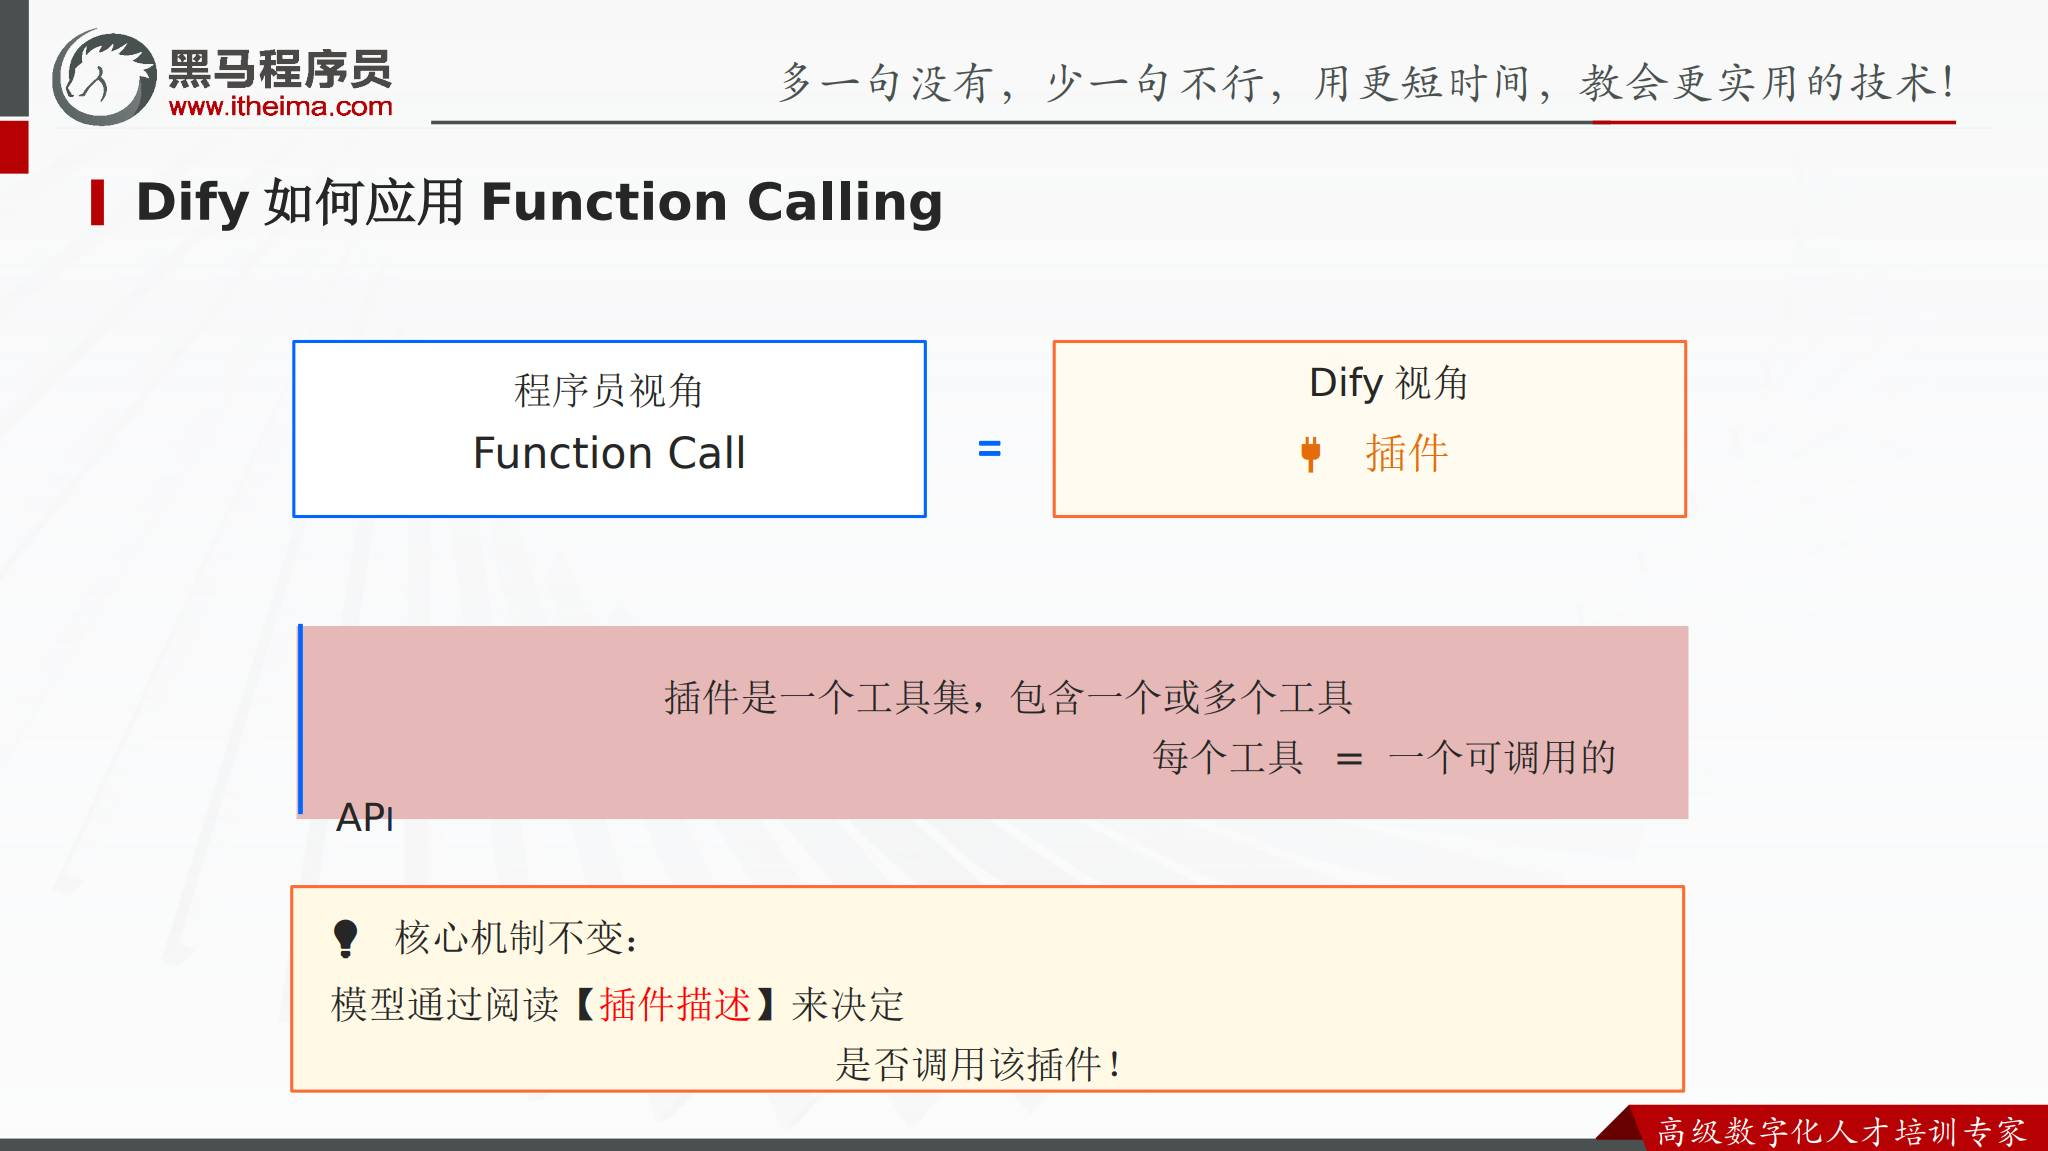


## 6. Dify 插件生态

课件把插件分为三类：

| 类型 | 说明 |
| --- | --- |
| 第三方免费插件 | 直接安装使用 |
| 第三方付费插件 | 通常需要申请并配置 API Key |
| 自定义插件 | 自己创建，接入需要的 API 或企业内部系统 |

常见工具类别包括：

- 信息查询：搜索、新闻、天气、地图。
- 数据分析：股票、汇率、图表生成。
- 内容创作：图片生成、视频编辑。
- 效率工具：邮件、日历、翻译、计算器。

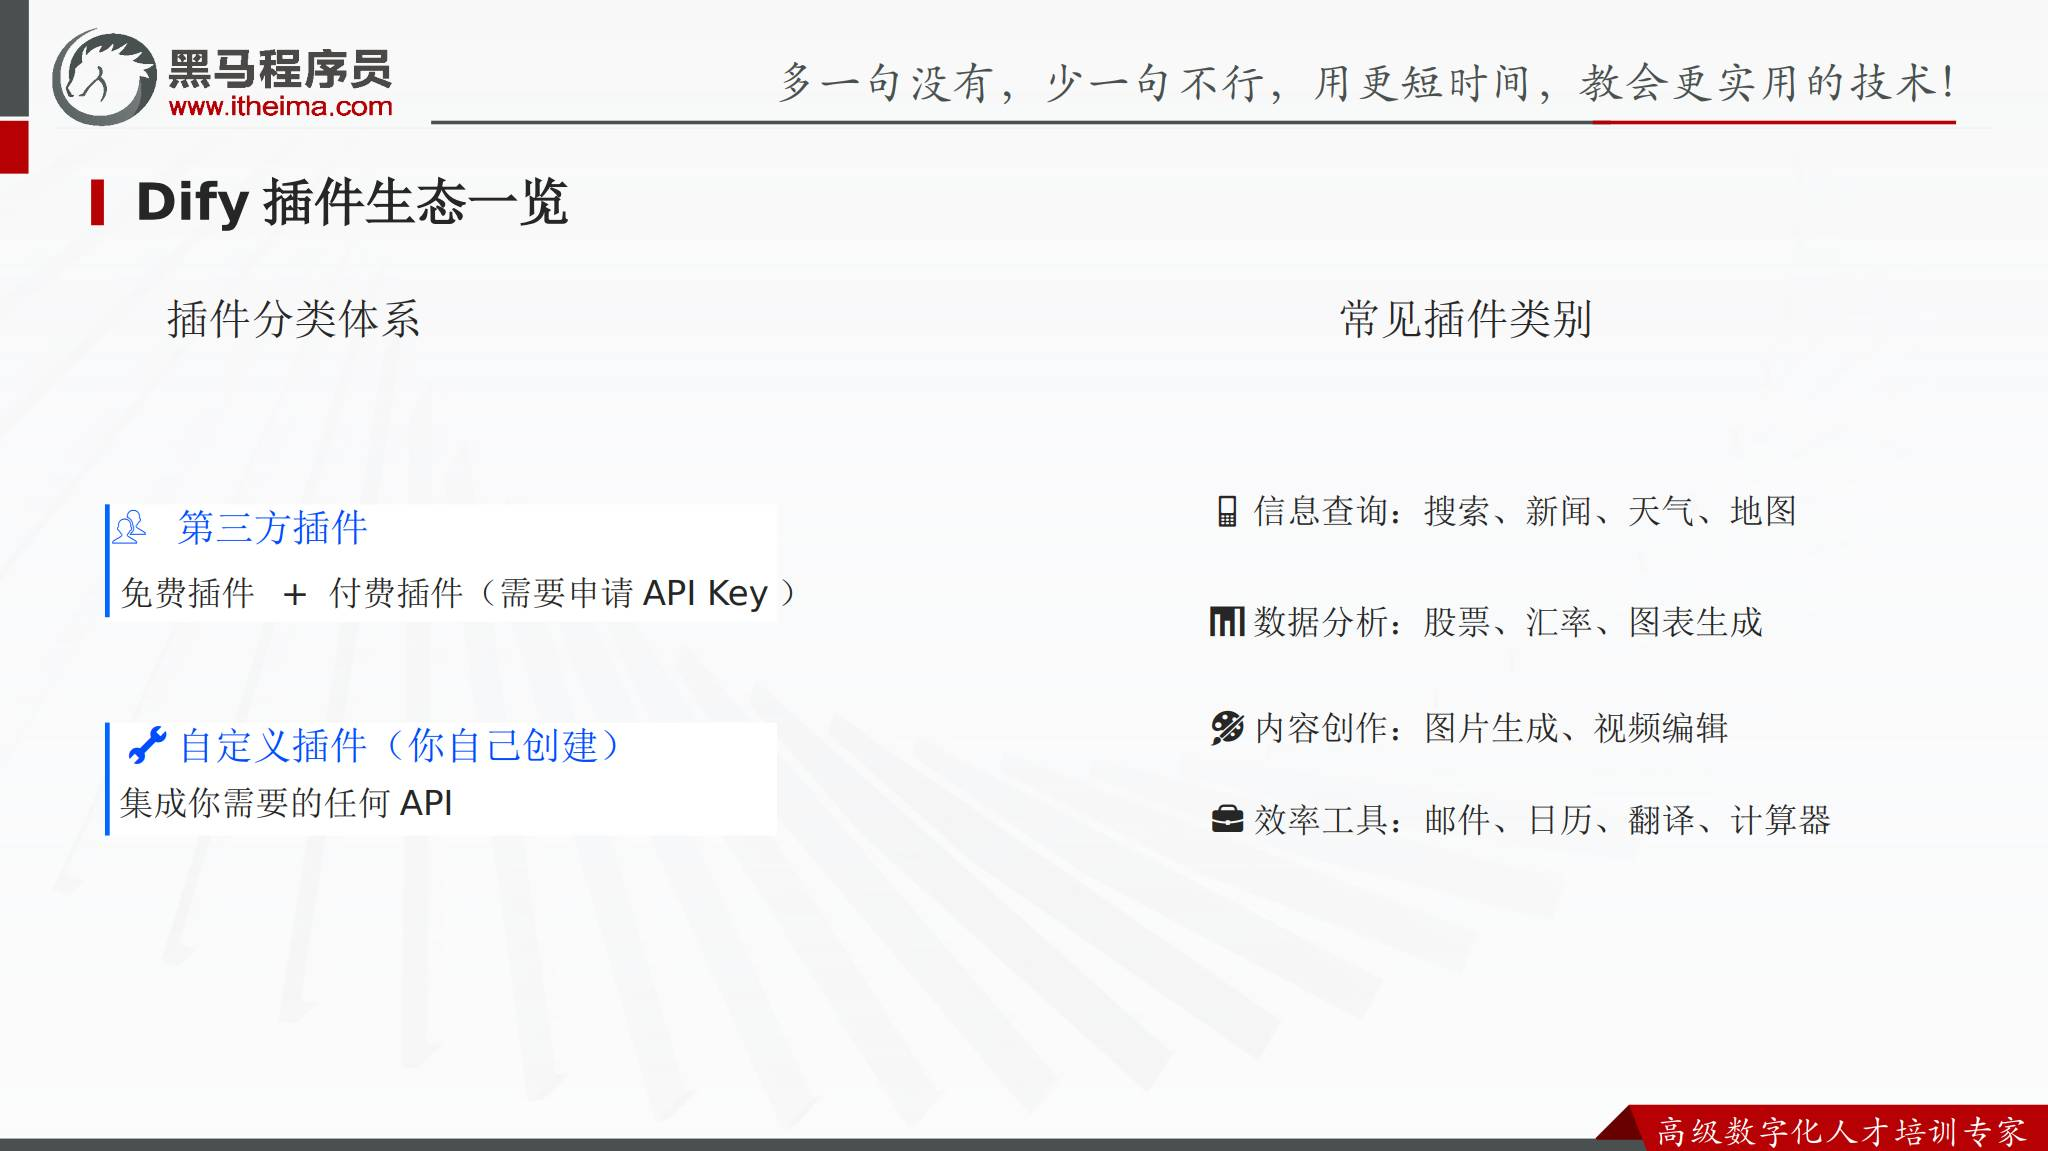


## 7. 使用现有插件：时间查询

课件先用一个简单任务演示已有插件：让 Agent 获取当前时间。基本操作顺序是：

1. 在 Dify 中找到需要的时间工具插件。
2. 创建或打开一个 Agent 应用。
3. 在应用的工具配置中选择该插件。
4. 输入“获取当前时间”之类的问题进行测试。

这个例子用来验证“模型判断需要工具、调用工具、根据工具结果回答”的完整链路。

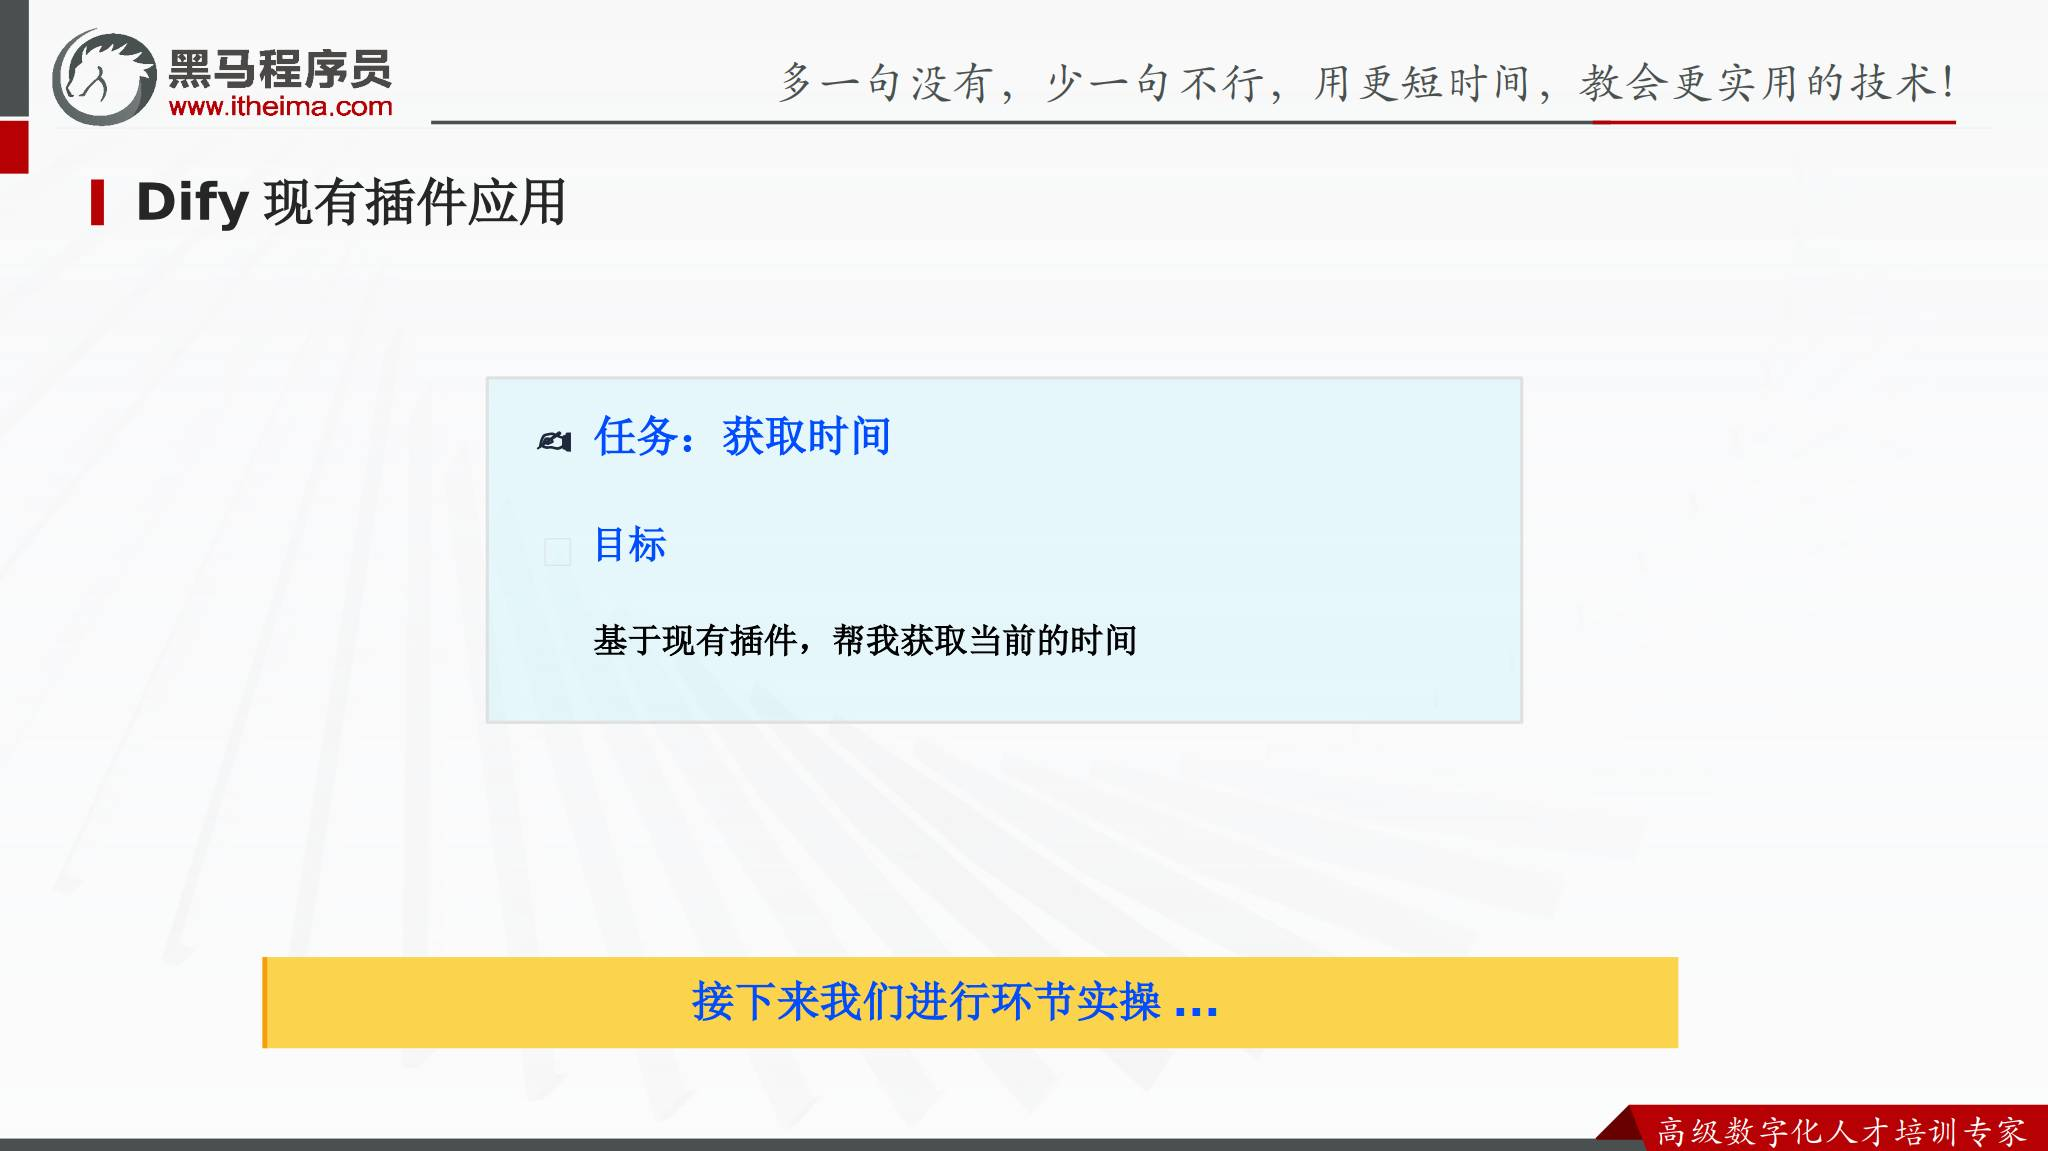


## 8. 插件与 Function Calling 的关系

在 Dify 中，工具或插件就是 Function Calling 的实现形式。课程总结的应用顺序是：

```text
选择工具 → 下载插件 → 创建 Agent → 选择插件 → 应用并测试
```

模型负责根据插件描述判断是否调用，Dify 负责把工具接入应用并组织调用结果。


## 9. 什么时候需要自定义插件

出现下面情况时，可以考虑创建自定义插件：

- 官方插件没有需要的功能。
- 付费插件成本过高。
- 需要连接特定的第三方 API 服务。
- 需要对接企业内部系统。

自定义插件的关键价值是把已有业务能力包装成 Dify 能够识别和调用的工具。

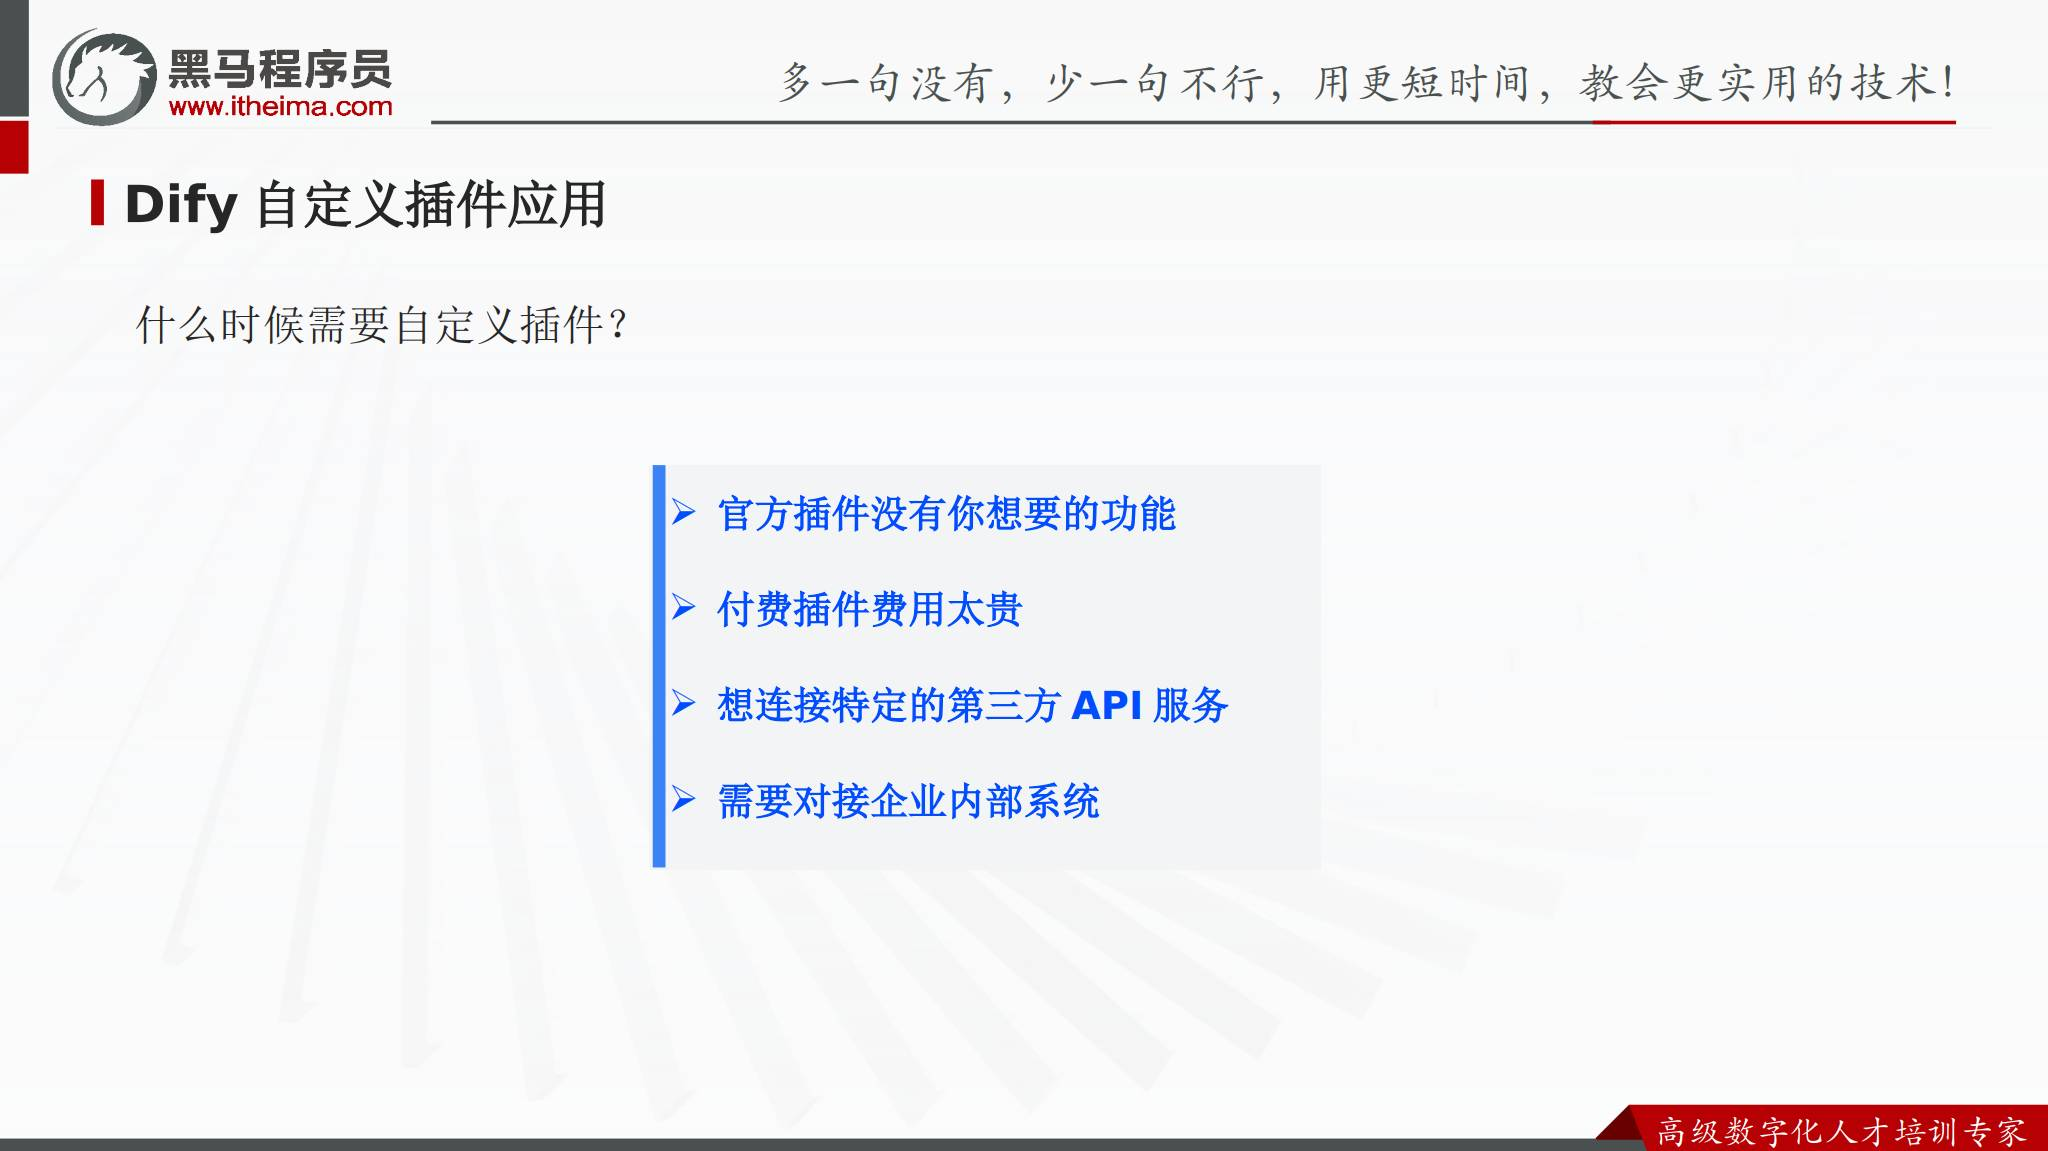


## 10. 自定义插件的基本流程

课件将自定义插件拆成六步：

1. **脚本开发**：在本地用 Python 编写实现业务逻辑的代码。
2. **运行脚本**：让脚本以 API 形式在后台运行。
3. **创建工具**：在 Dify 中选择“创建自定义工具”。
4. **Schema 操作**：配置 OpenAI Schema，描述工具名称、参数和返回约束。
5. **测试**：输入参数，验证工具是否能够正常工作。
6. **保存**：把工具保存到 Agent 中并在应用里使用。

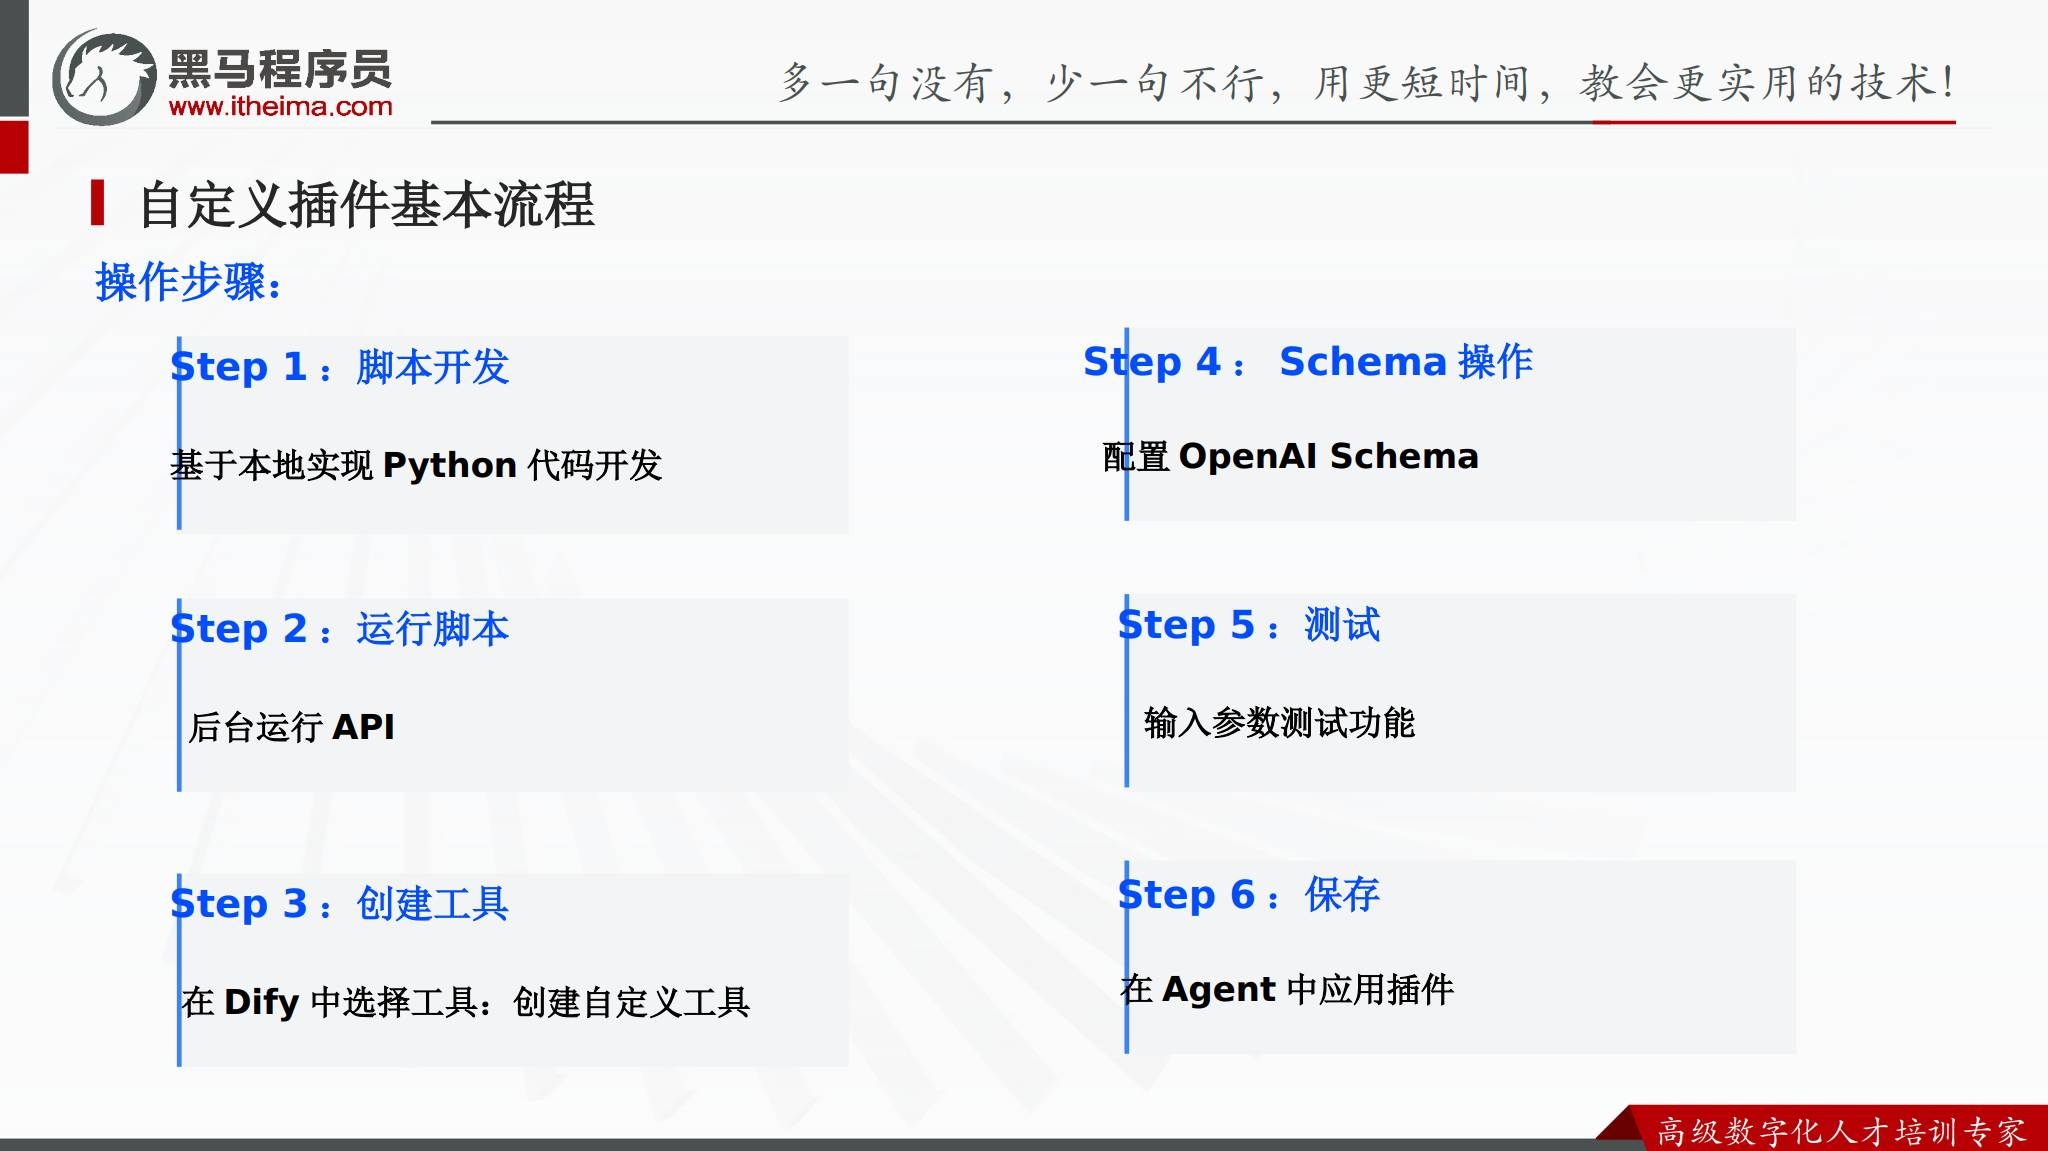


## 11. Schema 在自定义工具中的作用

Schema 是工具和模型之间的参数说明。它需要让模型知道：

- 工具能完成什么任务。
- 工具需要哪些参数。
- 每个参数是什么类型、代表什么含义。
- 哪些参数是必填项。

Schema 写得越清楚，模型越容易生成符合要求的调用参数。真正执行前，服务端仍然需要校验参数，不能把模型生成的参数直接视为可信输入。


## 12. 实战目标：智能天气助手

本章实战目标是制作一个天气查询插件，让 Agent 根据用户问题调用天气 API 并返回结果。

基本链路是：

```text
用户询问天气 → 模型判断需要天气工具 → 生成城市等参数 → 工具调用天气 API → 返回结果 → 模型组织回答
```

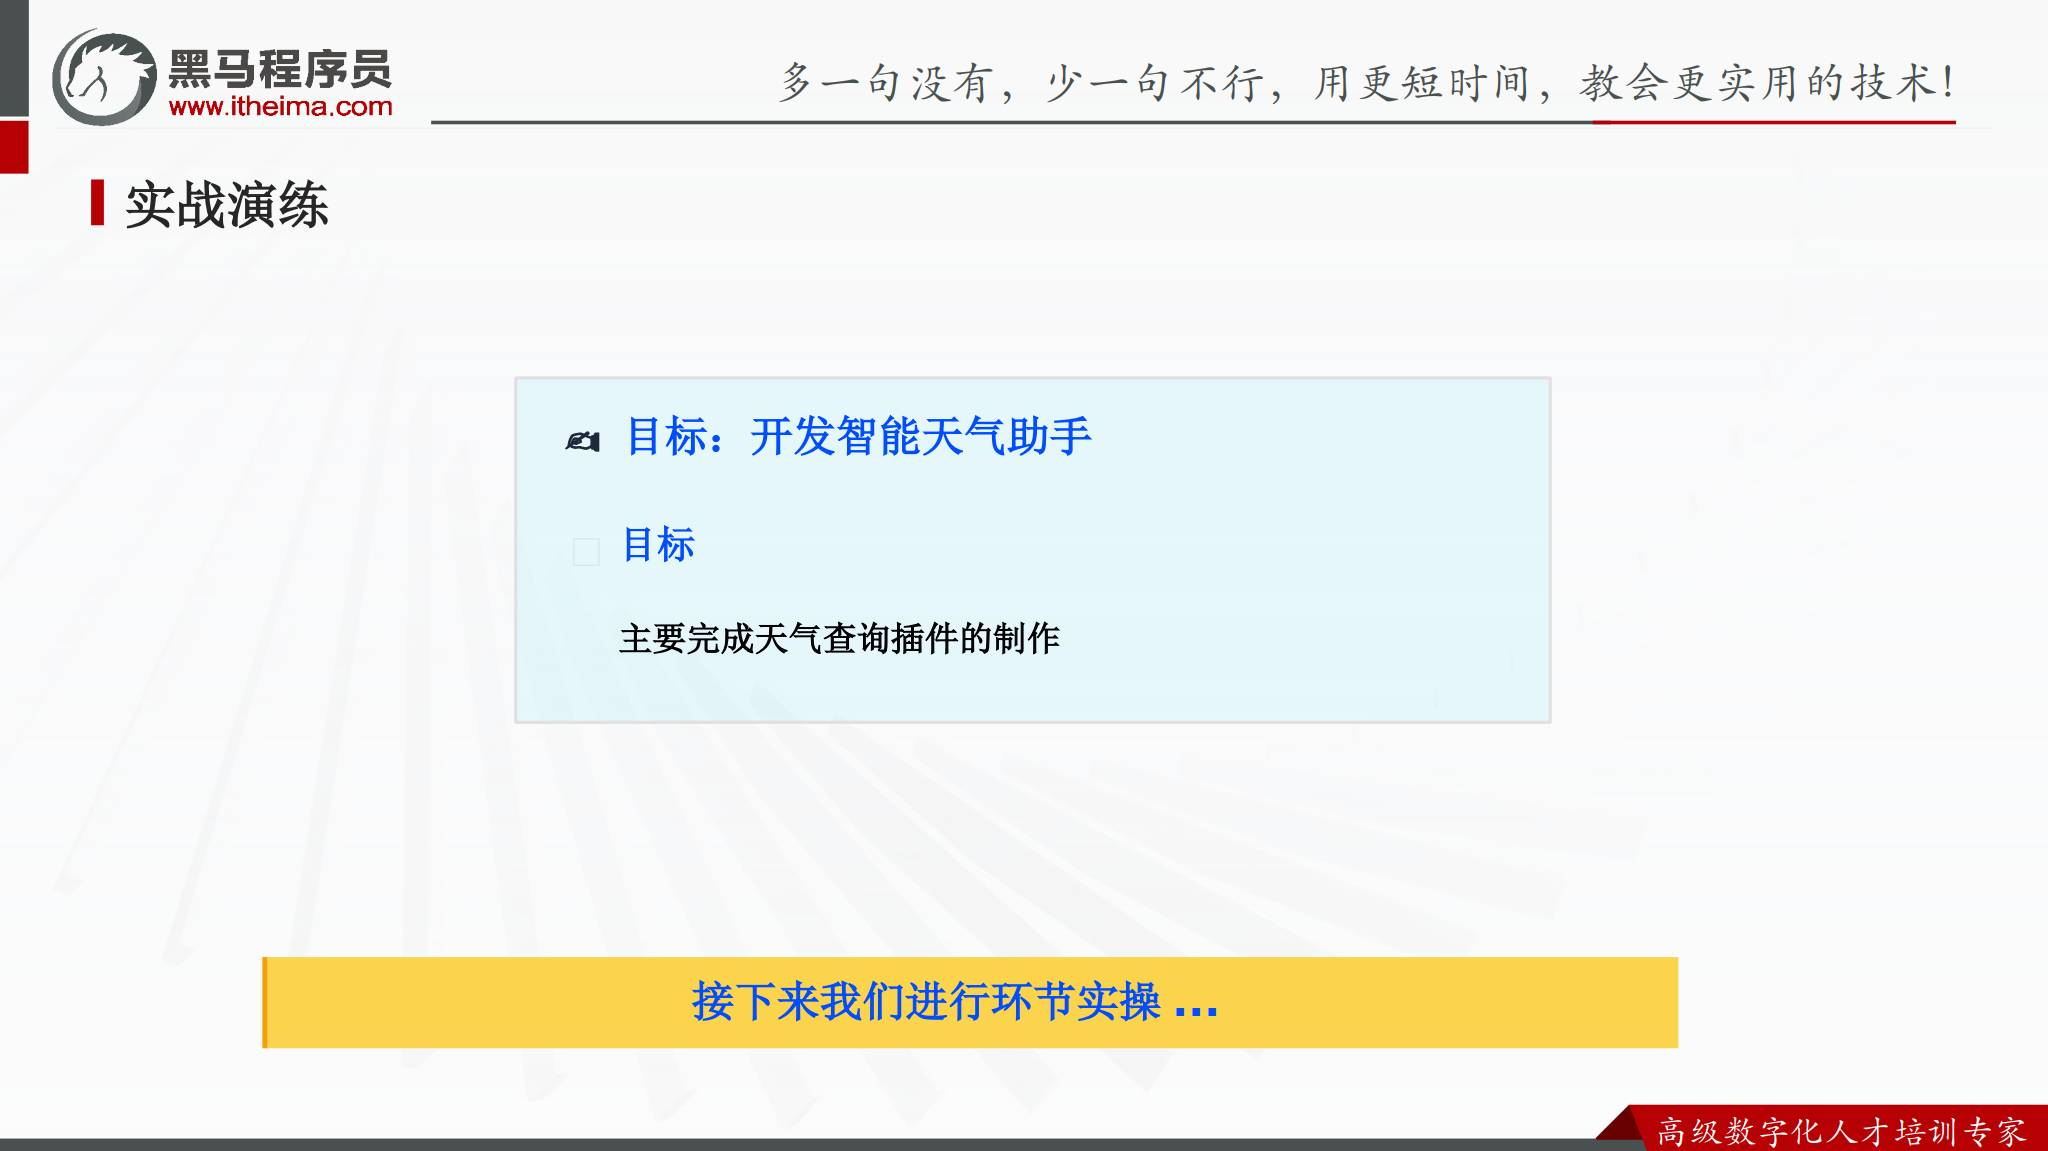


## 13. 天气助手的实现顺序

按照课件流程，可以这样组织实战：

1. 在本地完成天气查询 Python 脚本。
2. 把脚本运行成后台 API 服务。
3. 在 Dify 中创建自定义工具。
4. 根据 API 入参配置 OpenAI Schema。
5. 输入城市等参数测试工具功能。
6. 在 Agent 中保存并应用天气插件。

课件没有展开具体天气服务、接口地址和完整 Python 代码，因此本篇保留工具接入顺序与配置边界，不补写未经课件核对的 API 实现。


## 14. 本章小结

Function Calling 让模型具备调用外部工具的能力，但模型只返回调用参数，真正的函数执行由应用完成。在 Dify 中，插件就是 Function Calling 的工具化实现。自定义插件的主线是：Python 脚本开发、后台运行 API、创建自定义工具、配置 Schema、测试并保存到 Agent。

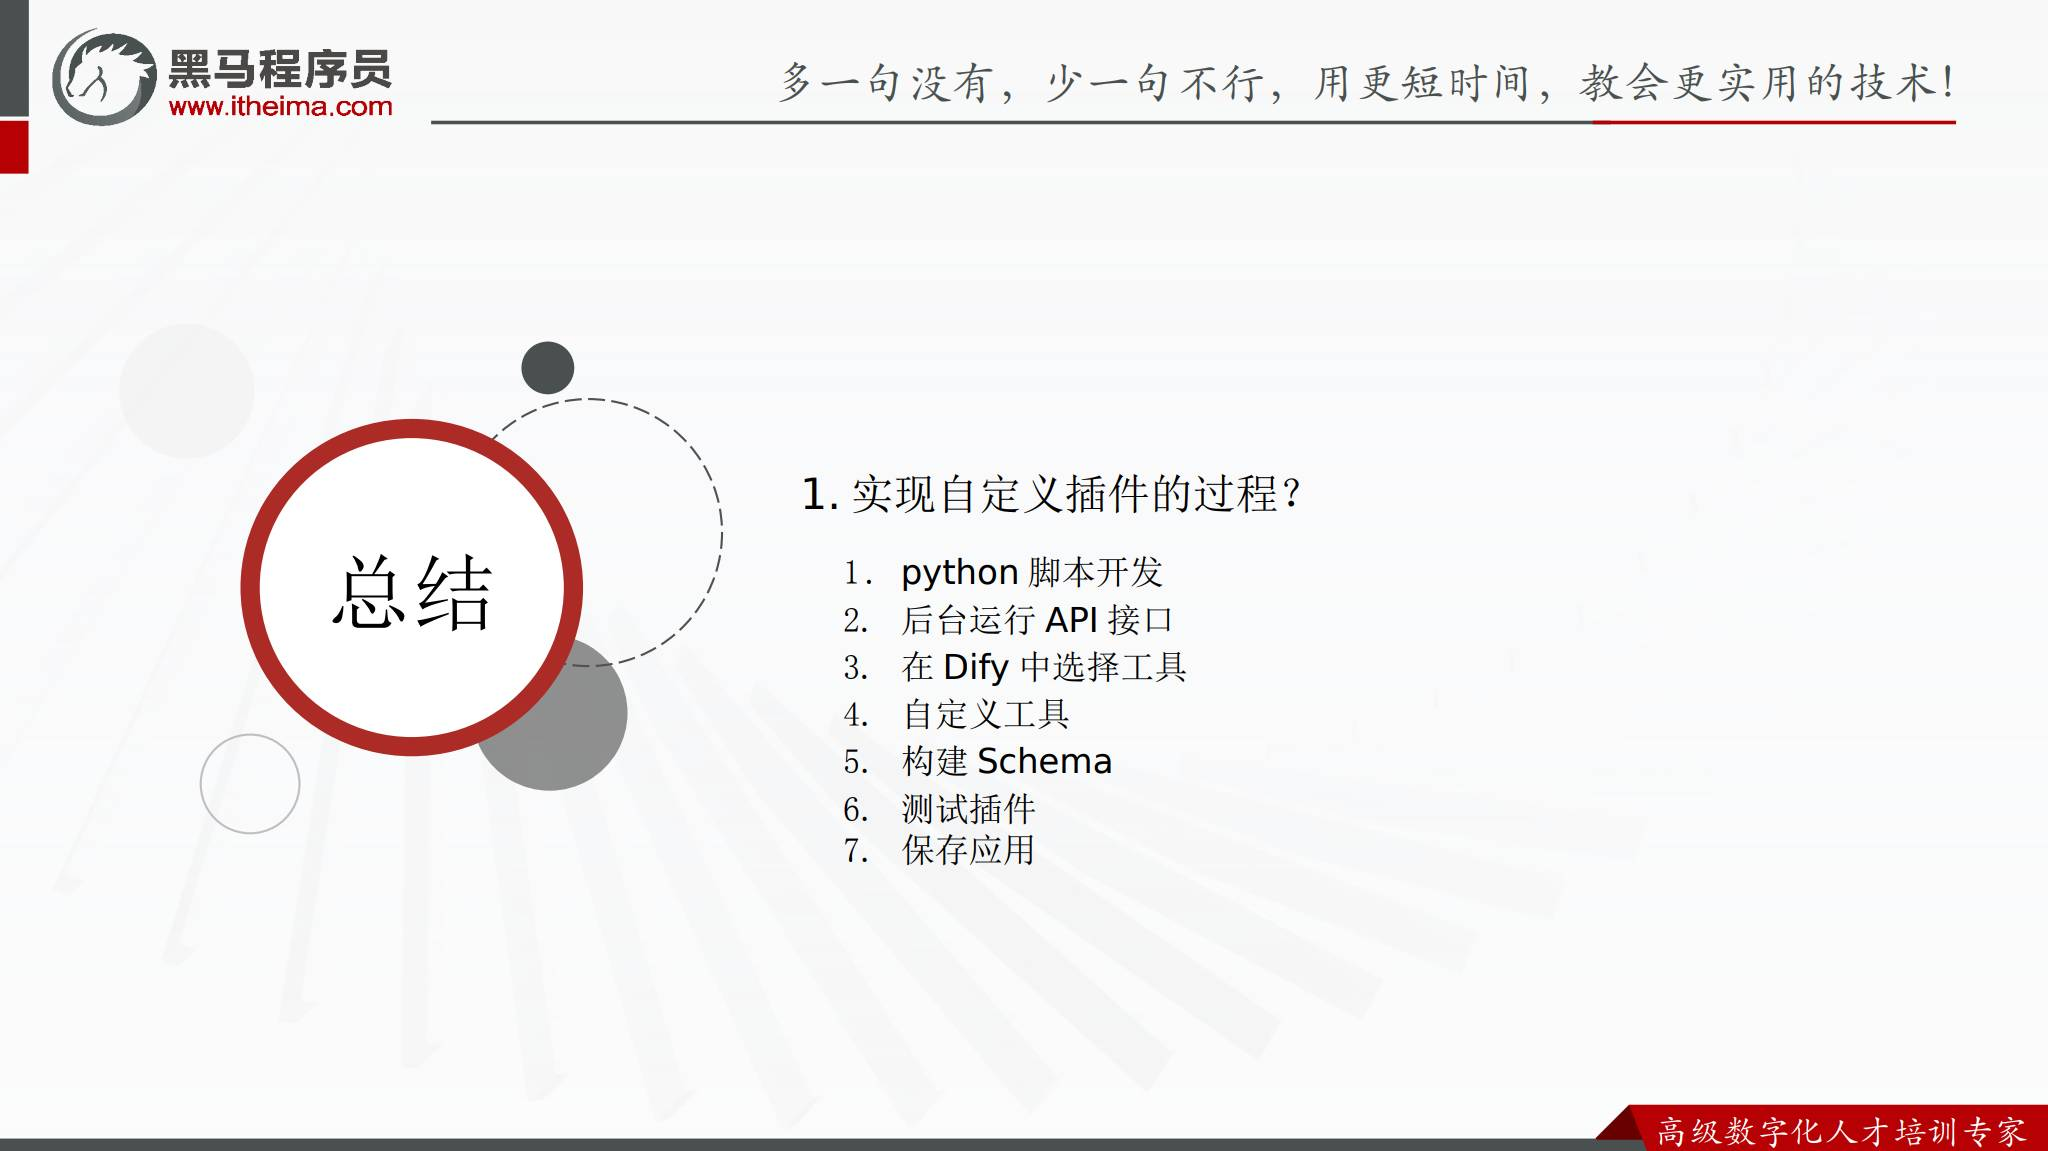


## 15. 资料边界

本篇依据第 5 章课件整理了 Function Calling 原理、Dify 插件生态、时间工具示例、自定义插件流程和天气助手目标。课件没有给出完整天气 API 代码、服务地址或具体 Schema JSON，因此没有把这些内容扩写成可直接运行的实现。
